<a href="https://colab.research.google.com/github/marisolgodoy/DL_Marisol_Godoy/blob/main/notebook_clase2_redes_neuronales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Clase 2 — ¿Qué es una Red Neuronal?
### Módulo 2: Deep Learning · Diplomatura en IA · UTN 2026

---

Este notebook es completamente introductorio. **No necesitás experiencia previa en programación avanzada.** El objetivo es ver cómo funciona una red neuronal *desde adentro*, de manera visual e intuitiva.

▶️ **Para ejecutar una celda:** seleccionala y presioná `Shift + Enter`

---

Marisol Godoy
Deep Learning - UTN

## Parte 0: El mapa del territorio — IA, ML y Deep Learning

Antes de escribir una sola línea de código, vamos a entender **dónde estamos parados**.

### Los tres círculos concéntricos

```
┌─────────────────────────────────────────┐
│         INTELIGENCIA ARTIFICIAL         │
│  (cualquier sistema que simula          │
│   inteligencia humana)                  │
│                                         │
│   ┌─────────────────────────────┐       │
│   │      MACHINE LEARNING       │       │
│   │  (aprende de datos, sin      │       │
│   │   reglas explícitas)         │       │
│   │                              │       │
│   │   ┌──────────────────┐       │       │
│   │   │  DEEP LEARNING   │ ← acá │       │
│   │   │  (redes neuro-   │       │       │
│   │   │   nales profund.) │       │       │
│   │   └──────────────────┘       │       │
│   └─────────────────────────────┘       │
└─────────────────────────────────────────┘
```

### ¿Qué es Machine Learning en una oración?

> **Programación tradicional:** vos escribís las reglas. La máquina las aplica.  
> **Machine Learning:** vos mostrás ejemplos. La máquina descubre las reglas sola.

### ¿Por qué Deep Learning y no ML clásico?

| Tarea | ¿Cuál usar? |
|-------|-------------|
| Predecir ventas en una planilla | ML clásico (ej: Random Forest) |
| Clasificar fotos de perros vs gatos | **Deep Learning** |
| Detectar fraude bancario | ML clásico o DL |
| Transcribir audio a texto | **Deep Learning** |
| Generar texto (ChatGPT) | **Deep Learning** |

**Regla general:** cuando los datos son imágenes, texto, audio o video → Deep Learning.  
Cuando son datos tabulares estructurados → el ML clásico suele alcanzar.

---

## Parte 1: La neurona artificial — una calculadora con "personalidad"

Una neurona artificial hace una sola cosa: **toma varias entradas, las multiplica por sus pesos, las suma y pasa el resultado por una función de activación**.

Vamos a construirla paso a paso.

In [1]:
# Paso 1: Instalar dependencias (solo en Colab)
# Si estás en tu PC con el ambiente ya configurado, podés saltear esta celda

# !pip install numpy matplotlib --quiet

import numpy as np
import matplotlib.pyplot as plt

print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


In [2]:
# ─── NUESTRO EJEMPLO: ¿Aprobará el examen? ──────────────────────────
#
# Un estudiante estudió 8 horas y durmió bien la noche anterior.
# ¿Nuestra neurona predice que va a aprobar?

# Entradas
x1 = 8   # horas de estudio
x2 = 1   # durmió bien: sí=1, no=0

# Pesos (qué tan importante es cada factor)
w1 = 0.7  # las horas de estudio importan bastante
w2 = 0.5  # dormir bien también importa

# Sesgo (ajusta el umbral de activación)
b = -3.0  # sin suficiente estudio, la neurona no se activa

# ─── EL CÁLCULO ─────────────────────────────────────────────────────
z = w1 * x1 + w2 * x2 + b

print(f"Suma ponderada z = {w1}×{x1} + {w2}×{x2} + ({b}) = {z}")

Suma ponderada z = 0.7×8 + 0.5×1 + (-3.0) = 3.0999999999999996


### La función de activación: el "umbral de decisión"

El valor `z = 3.1` en sí mismo no dice mucho. Necesitamos una **función de activación** para convertirlo en algo interpretable.

La función **Sigmoid** lo convierte en un número entre 0 y 1 → una probabilidad:

In [3]:
def sigmoid(z):
    """Función Sigmoid: convierte cualquier número en un valor entre 0 y 1"""
    return 1 / (1 + np.exp(-z))

probabilidad = sigmoid(z)

print(f"z = {z:.2f}")
print(f"sigmoid({z:.2f}) = {probabilidad:.4f}")
print(f"\nInterpretación: hay un {probabilidad*100:.1f}% de probabilidad de que apruebe")

if probabilidad >= 0.5:
    print("\n✅ La neurona predice: APRUEBA")
else:
    print("\n❌ La neurona predice: NO APRUEBA")

z = 3.10
sigmoid(3.10) = 0.9569

Interpretación: hay un 95.7% de probabilidad de que apruebe

✅ La neurona predice: APRUEBA


### 🧪 Experimento: ¿qué pasa si el estudiante NO durmió bien?

Modificá el valor de `x2 = 0` y volvé a ejecutar. ¿Cambia la predicción?

In [4]:
# ✏️ MODIFICÁ LOS VALORES Y OBSERVÁ QUÉ CAMBIA
x1 = 8   # horas de estudio ← probá con 2, 5, 10
x2 = 0   # ¿durmió bien? ← probá con 0 (no)

# (no modificar desde acá)
z = w1 * x1 + w2 * x2 + b
prob = sigmoid(z)

print(f"Estudiante: {x1} horas de estudio, {'durmió bien' if x2 else 'no durmió bien'}")
print(f"z = {z:.2f}  →  probabilidad = {prob*100:.1f}%")
print(f"Predicción: {'✅ APRUEBA' if prob >= 0.5 else '❌ NO APRUEBA'}")

Estudiante: 8 horas de estudio, no durmió bien
z = 2.60  →  probabilidad = 93.1%
Predicción: ✅ APRUEBA


---
## Parte 2: Visualizando las funciones de activación

Hay varias funciones de activación. Las más comunes son Sigmoid, ReLU y Tanh. Cada una tiene propiedades distintas.

El siguiente gráfico las compara lado a lado:

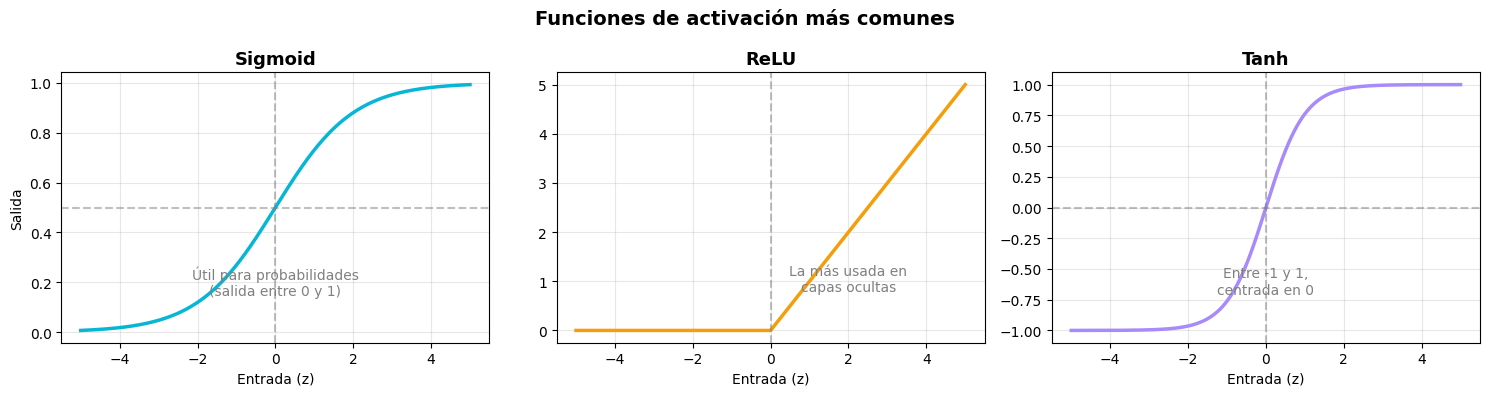

✅ Gráfico guardado como 'activations.png'


In [5]:
z_values = np.linspace(-5, 5, 300)

def relu(z):
    """ReLU: si z < 0 → 0, si z >= 0 → z"""
    return np.maximum(0, z)

def tanh(z):
    """Tangente hiperbólica: entre -1 y 1"""
    return np.tanh(z)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Funciones de activación más comunes", fontsize=14, fontweight='bold')

# Sigmoid
axes[0].plot(z_values, sigmoid(z_values), color='#06B6D4', linewidth=2.5)
axes[0].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
axes[0].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
axes[0].set_title('Sigmoid', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Salida')
axes[0].set_xlabel('Entrada (z)')
axes[0].annotate('Útil para probabilidades\n(salida entre 0 y 1)',
                  xy=(0, 0.15), fontsize=10, color='gray', ha='center')
axes[0].grid(alpha=0.3)

# ReLU
axes[1].plot(z_values, relu(z_values), color='#F59E0B', linewidth=2.5)
axes[1].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
axes[1].set_title('ReLU', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Entrada (z)')
axes[1].annotate('La más usada en\ncapas ocultas',
                  xy=(2, 0.8), fontsize=10, color='gray', ha='center')
axes[1].grid(alpha=0.3)

# Tanh
axes[2].plot(z_values, tanh(z_values), color='#A78BFA', linewidth=2.5)
axes[2].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
axes[2].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
axes[2].set_title('Tanh', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Entrada (z)')
axes[2].annotate('Entre -1 y 1,\ncentrada en 0',
                  xy=(0, -0.7), fontsize=10, color='gray', ha='center')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('activations.png', dpi=120, bbox_inches='tight')
plt.show()
print("✅ Gráfico guardado como 'activations.png'")

---
## Parte 3: Una red neuronal simple — sin librerías

Ahora vamos a construir una red neuronal **mínima** a mano, para ver exactamente qué pasa en cada paso.

Nuestra red tiene:
- **2 entradas** (x₁, x₂)
- **1 capa oculta** con 3 neuronas
- **1 salida** (clasificación binaria)

```
Entrada (2)  →  Capa oculta (3 neuronas)  →  Salida (1)
```

In [6]:
np.random.seed(42)  # Para reproducibilidad

# ─── PESOS (inicializados aleatoriamente, como hace la red al comenzar) ───
# Capa 1: 2 entradas → 3 neuronas ocultas
W1 = np.random.randn(2, 3) * 0.5   # Matriz de pesos 2×3
b1 = np.zeros(3)                    # Sesgos de la capa oculta

# Capa 2: 3 neuronas ocultas → 1 salida
W2 = np.random.randn(3, 1) * 0.5   # Matriz de pesos 3×1
b2 = np.zeros(1)                    # Sesgo de la salida

print("Pesos iniciales de la Capa 1 (W1):")
print(W1)
print(f"\nSesgos iniciales de la Capa 1 (b1): {b1}")
print(f"\nNota: estos valores son ALEATORIOS — el entrenamiento los ajustará")

Pesos iniciales de la Capa 1 (W1):
[[ 0.24835708 -0.06913215  0.32384427]
 [ 0.76151493 -0.11707669 -0.11706848]]

Sesgos iniciales de la Capa 1 (b1): [0. 0. 0.]

Nota: estos valores son ALEATORIOS — el entrenamiento los ajustará


In [7]:
def forward_pass(X, W1, b1, W2, b2):
    """
    Propagación hacia adelante (Forward Pass).
    Calcula la predicción de la red para una entrada X.
    """
    # Capa 1: suma ponderada + activación ReLU
    z1 = np.dot(X, W1) + b1      # suma ponderada
    a1 = relu(z1)                 # activación

    # Capa 2 (salida): suma ponderada + activación Sigmoid
    z2 = np.dot(a1, W2) + b2     # suma ponderada
    a2 = sigmoid(z2)             # activación → probabilidad

    return a1, a2

# ─── PROBEMOS CON UN ESTUDIANTE ──────────────────────────────────────
X_test = np.array([8, 1])   # 8 horas de estudio, durmió bien

a1, prediccion = forward_pass(X_test, W1, b1, W2, b2)

print(f"Entrada: {X_test}")
print(f"Activaciones capa oculta: {a1.round(3)}")
print(f"Predicción final: {prediccion[0]:.4f} ({prediccion[0]*100:.1f}% de probabilidad)")
print(f"\n⚠️  Con pesos ALEATORIOS, la red predice cualquier cosa.")
print(f"   Necesita ENTRENAMIENTO para aprender.")

Entrada: [8 1]
Activaciones capa oculta: [2.748 0.    2.474]
Predicción final: 0.8305 (83.1% de probabilidad)

⚠️  Con pesos ALEATORIOS, la red predice cualquier cosa.
   Necesita ENTRENAMIENTO para aprender.


---
## Parte 4: El entrenamiento — ajustando los pesos

Veamos el ciclo de entrenamiento con un dataset pequeño y controlado.

**Problema:** clasificar si un punto (x₁, x₂) pertenece a la clase 0 o la clase 1.

Dataset:
  x1  x2  |  y
  -------- | ---
   0   0  |   0
   0   1  |   1
   1   0  |   1
   1   1  |   0


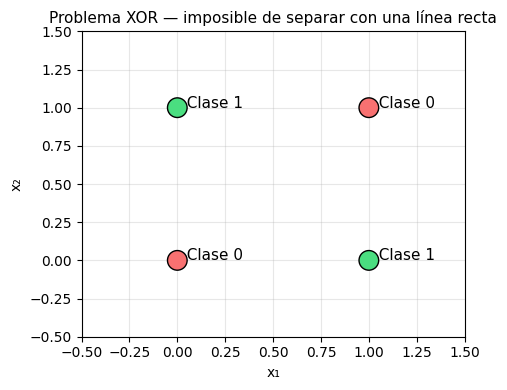

In [8]:
# Dataset simple: 4 ejemplos, problema tipo XOR
# (x1, x2) → y
X = np.array([
    [0, 0],   # Ejemplo 1
    [0, 1],   # Ejemplo 2
    [1, 0],   # Ejemplo 3
    [1, 1],   # Ejemplo 4
])

y = np.array([[0], [1], [1], [0]])   # Etiquetas verdaderas

print("Dataset:")
print("  x1  x2  |  y")
print("  -------- | ---")
for i in range(len(X)):
    print(f"   {X[i,0]}   {X[i,1]}  |   {y[i,0]}")

# Visualización
fig, ax = plt.subplots(figsize=(5, 4))
colors = ['#F87171' if label == 0 else '#4ADE80' for label in y.flatten()]
ax.scatter(X[:, 0], X[:, 1], c=colors, s=200, edgecolors='black', zorder=5)

for i, (xi, yi) in enumerate(zip(X, y)):
    ax.annotate(f'  Clase {yi[0]}', (xi[0], xi[1]), fontsize=11)

ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_xlabel('x₁')
ax.set_ylabel('x₂')
ax.set_title('Problema XOR — imposible de separar con una línea recta', fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# ─── ENTRENAMIENTO SIMPLIFICADO ──────────────────────────────────────
#
# Aquí usamos una implementación manual del loop de entrenamiento.
# En la próxima clase usaremos Keras que hace esto automáticamente.

np.random.seed(42)
W1 = np.random.randn(2, 3) * 0.5
b1 = np.zeros(3)
W2 = np.random.randn(3, 1) * 0.5
b2 = np.zeros(1)

lr = 0.5          # learning rate (tasa de aprendizaje)
epochs = 5000     # iteraciones de entrenamiento
losses = []

for epoch in range(epochs):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = relu(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Calcular error (Binary Cross-Entropy)
    loss = -np.mean(y * np.log(a2 + 1e-9) + (1 - y) * np.log(1 - a2 + 1e-9))
    losses.append(loss)

    # Backward pass (gradientes)
    dL_da2 = -(y / (a2 + 1e-9)) + ((1 - y) / (1 - a2 + 1e-9))
    dL_dz2 = dL_da2 * a2 * (1 - a2)
    dL_dW2 = np.dot(a1.T, dL_dz2) / len(X)
    dL_db2 = dL_dz2.mean(axis=0)

    dL_da1 = np.dot(dL_dz2, W2.T)
    dL_dz1 = dL_da1 * (z1 > 0).astype(float)
    dL_dW1 = np.dot(X.T, dL_dz1) / len(X)
    dL_db1 = dL_dz1.mean(axis=0)

    # Actualizar pesos
    W2 -= lr * dL_dW2
    b2 -= lr * dL_db2
    W1 -= lr * dL_dW1
    b1 -= lr * dL_db1

print("Entrenamiento completo ✅")
print(f"Error inicial:  {losses[0]:.4f}")
print(f"Error final:    {losses[-1]:.4f}")
print(f"\n¡El error bajó un {(1 - losses[-1]/losses[0])*100:.1f}%!")

Entrenamiento completo ✅
Error inicial:  0.7253
Error final:    0.6931

¡El error bajó un 4.4%!


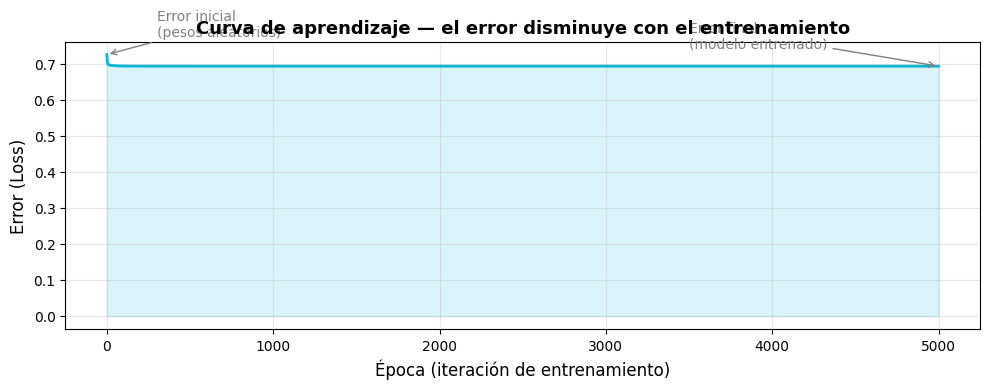

In [11]:
# ─── CURVA DE APRENDIZAJE ────────────────────────────────────────────
# Este gráfico muestra cómo el error disminuye con el entrenamiento.
# Es UNA de las visualizaciones más importantes en Deep Learning.

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses, color='#06B6D4', linewidth=2)
ax.fill_between(range(len(losses)), losses, alpha=0.15, color='#06B6D4')
ax.set_xlabel('Época (iteración de entrenamiento)', fontsize=12)
ax.set_ylabel('Error (Loss)', fontsize=12)
ax.set_title('Curva de aprendizaje — el error disminuye con el entrenamiento', fontsize=13, fontweight='bold')

# Annotations
ax.annotate('Error inicial\n(pesos aleatorios)',
             xy=(0, losses[0]), xytext=(300, losses[0]+0.05),
             arrowprops=dict(arrowstyle='->', color='gray'),
             fontsize=10, color='gray')
ax.annotate('Error final\n(modelo entrenado)',
             xy=(epochs-1, losses[-1]), xytext=(epochs-1500, losses[-1]+0.05),
             arrowprops=dict(arrowstyle='->', color='gray'),
             fontsize=10, color='gray')

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# ─── PREDICCIONES FINALES ────────────────────────────────────────────
_, predicciones = forward_pass(X, W1, b1, W2, b2)

print("Predicciones del modelo entrenado:")
print("  x1  x2  |  y real  |  predicción  |  resultado")
print("  -------- | -------- | ------------ | ----------")
for i in range(len(X)):
    pred = predicciones[i, 0]
    clase_pred = 1 if pred >= 0.5 else 0
    correcto = "✅" if clase_pred == y[i, 0] else "❌"
    print(f"   {X[i,0]}   {X[i,1]}  |     {y[i,0]}    |   {pred:.2f} → {clase_pred}    |   {correcto}")

Predicciones del modelo entrenado:
  x1  x2  |  y real  |  predicción  |  resultado
  -------- | -------- | ------------ | ----------
   0   0  |     0    |   0.50 → 0    |   ✅
   0   1  |     1    |   0.50 → 1    |   ✅
   1   0  |     1    |   0.50 → 0    |   ❌
   1   1  |     0    |   0.50 → 1    |   ❌


---
## Parte 5: Tu turno — explorá el TF Playground

El código que acabás de ver es exactamente lo que hace TensorFlow Playground de forma visual.

### Abrí este link en una nueva pestaña:
**https://playground.tensorflow.org**

### Desafíos para explorar:

1. **Seleccioná el dataset "Spiral"** (el espiral de dos colores). Es el más difícil.
2. **Presioná ▶ con 1 sola capa oculta y 2 neuronas** — ¿puede aprender la espiral?
3. **Agregá más capas** (4 capas, 4 neuronas cada una) — ¿mejora?
4. **Cambiá el Learning Rate a 10** — ¿qué pasa? ¿Y si lo bajás a 0.001?
5. **Cambiá la función de activación de ReLU a Linear** — ¿por qué no aprende?

### Preguntas para reflexionar:
- ¿Por qué el problema "Spiral" necesita más capas que el problema "Circle"?
- ¿Qué pasa con el error de entrenamiento (Training loss) vs el de prueba (Test loss)?
- ¿Podés encontrar una configuración que aprenda la espiral en menos de 100 épocas?


---
## Resumen de lo que aprendiste en esta clase

| Concepto | Descripción |
|----------|-------------|
| **Neurona artificial** | Calcula `z = w₁x₁ + w₂x₂ + b` y aplica una función de activación |
| **Peso (w)** | Indica cuánto importa cada entrada para la predicción |
| **Sesgo (b)** | Ajusta el umbral de activación |
| **Función de activación** | Sigmoid (probabilidad), ReLU (capas ocultas), Tanh |
| **Red neuronal** | Capas de neuronas: entrada → ocultas → salida |
| **Entrenamiento** | Loop: forward pass → calcular error → backward pass → actualizar pesos |
| **Curva de aprendizaje** | Gráfico del error vs épocas — queremos que baje |

---
**Próxima clase:** El perceptrón en detalle + nuestro primer modelo con Keras (sin programar a mano el backpropagation 😅)